# The probabilistic decoders

Most decoders average the data of a cell. The *drawing* decoders return one of them instead, chosen
at random with the same weights an average would use. Each member of the ensemble is then a value
that was observed, and the collection of members becomes a law to read in full, not only through
its mean. Here we look at all of them, `draw`, `wdraw_idw`, `wdraw_kriging`,
`wdraw_adaptiveidw` and `wdraw_sharpidw`, on a field whose truth we know.

## Learning goals

- What a drawing decoder returns, and how its members relate to those of the averaging decoder with
  the same weights.
- Why the draws give intervals that cover the truth far more often.
- How to read the law the members give, through quantiles, probabilities of exceedance and
  calibration.
- How the draws pair with the treatment of cells without data, what makes their results
  reproducible, and what they cost.

*When should an ensemble draw its members instead of averaging them, and how should we read it?*

## The idea

An averaging decoder with weights $\varpi_j(v)$ on the data $z_j$ of the cell of $v$ returns

$$g(v) = \sum_j \varpi_j(v)\, z_j .$$

Its drawing counterpart returns one datum, $z_J$, with $\Pr(J = j) = \varpi_j(v)$, drawn afresh at
every location and every partition. Within one partition its mean and variance are

$$\mathbb E\big[z_J\big] = g(v), \qquad \operatorname{Var}\big[z_J\big] = \sum_j \varpi_j(v)\, \big(z_j - g(v)\big)^2 .$$

So the draw keeps the averaging decoder's prediction in the mean, while its spread adds the weighted
dispersion of the values inside the cell, which the average throws away. Over the partitions, the
members of the averaging decoder vary only because the cells vary. Those of the draw vary for that
reason and also because the values within a cell differ, so the ensemble carries both sources of
uncertainty without anything added afterwards.

The weights name the decoders. `draw` gives every datum of the cell the same weight, which is the
theory's block-mark decoder, while `wdraw_idw`, `wdraw_kriging`, `wdraw_adaptiveidw` and
`wdraw_sharpidw` use the weights of the decoder named (kriging's made non-negative first). The theory
page [The block-mark model](https://spatialize.readthedocs.io/en/latest/theory/blockmark.html) gives the
law these decoders estimate.

## Step by step

### The data

The field is the anisotropic Gaussian simulation used across this gallery, 400 data on a 200 × 200
grid. Its correlation has a direction, so we use the decoders that fit one, the adaptive and sharpened
IDW and their draws, with the uniform draw alongside. The granularity is the knee of the Pareto search
of the tutorial on decoders.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

import spatialize
from spatialize.data import load_simulated_anisotropic_data
from spatialize.evaluation import MAE
from spatialize.gs.esi import esi_griddata, esi_nongriddata

spatialize.session.set(empty_cells="coarsen", progress=False)

(samples, _), _, _, grid = load_simulated_anisotropic_data()
points, values = samples[["x", "y"]].values, samples["sim1"].values
truth = grid["sim1"].values.reshape(200, 200).T            # truth[i, j] at x = i, y = j
xi = np.stack(np.meshgrid(np.arange(200.0), np.arange(200.0), indexing="ij"))
alpha = 0.95

### The identities, checked

At three locations we draw 4 000 partitions with the same seed, so that the adaptive IDW and its draw
see the same cells, and compare the mean and variance of their members.

In [2]:
spots = np.array([[50.0, 50.0], [120.0, 80.0], [160.0, 170.0]])
kw = dict(n_partitions=4000, alpha=alpha, seed=0)
averaged = esi_nongriddata(points, values, spots, local_interpolator="adaptiveidw", **kw).esi_samples()
drawn = esi_nongriddata(points, values, spots, local_interpolator="wdraw_adaptiveidw", **kw).esi_samples()
pd.DataFrame({"mean, averaging": averaged.mean(1), "mean, draw": drawn.mean(1),
              "standard error of the draw's mean": drawn.std(1) / np.sqrt(drawn.shape[1]),
              "variance, averaging": averaged.var(1), "variance, draw": drawn.var(1)},
             index=[f"({x:.0f}, {y:.0f})" for x, y in spots]).round(3)

,"mean, averaging","mean, draw",standard error of the draw's mean,"variance, averaging","variance, draw"
"(50, 50)",-0.194,-0.201,0.005,0.049,0.111
"(120, 80)",-0.609,-0.612,0.016,0.614,1.068
"(160, 170)",1.807,1.794,0.011,0.280,0.482


In [3]:
observed = np.isin(drawn, values.astype(np.float32)).mean()
print(f"share of the draw's members that are observed values {observed:.0%}")

share of the draw's members that are observed values 100%


The means agree within one or two standard errors, as the identity says, while the draw's variance is
larger at every location, by the dispersion within the cells. Every member of the draw is one of the
400 data.

### Five decoders, three measures

We now estimate the whole grid with the two averaging decoders and the three drawing ones, and judge
each by the error of its map, the coverage of its 90 % interval, and the Brier score of its
probability that the field exceeds 1, the mean squared difference between that probability and the
event, lower being better.

In [4]:
decoders = ["adaptiveidw", "sharpidw", "wdraw_adaptiveidw", "wdraw_sharpidw", "draw"]
results, rows = {}, {}
for name in decoders:
    start = time.perf_counter()
    r = esi_griddata(points, values, xi, local_interpolator=name, n_partitions=200, alpha=alpha, seed=0)
    elapsed = time.perf_counter() - start
    members = r.esi_samples()
    low, high = np.nanpercentile(members, [5, 95], axis=-1)
    exceed = np.mean(members > 1.0, axis=-1)
    results[name] = r
    rows[name] = {"true MAE": round(MAE(truth.ravel(), r.estimation().ravel()), 4),
                  "90 % coverage": round(np.mean((truth >= low) & (truth <= high)), 2),
                  "Brier score, Z > 1": round(np.mean((exceed - (truth > 1.0)) ** 2), 4),
                  "seconds": round(elapsed, 1)}
pd.DataFrame(rows).T

,true MAE,90 % coverage,"Brier score, Z > 1",seconds
adaptiveidw,0.4520,0.61,0.0878,2.9
sharpidw,0.4499,0.64,0.0852,2.8
wdraw_adaptiveidw,0.4527,0.76,0.0835,2.9
wdraw_sharpidw,0.4509,0.78,0.0836,2.9
draw,0.5190,0.88,0.0931,0.3


Coverage climbs in the order the theory predicts. The averaging decoders cover about 60 %, the
sharpened one a little more, the weighted draws about three quarters, and the uniform draw close to the
nominal 90 %. The weighted draws keep almost the map of their averaging counterparts while giving the
best probability of exceedance. The uniform draw, with equal weights, covers the most while giving the
least accurate map. The draws cost no more time than the decoders whose weights they use.

### Is the law calibrated?

The coverage of one interval is a single number. The *probability integral transform* checks the whole
law. At each location it reads the share of members below the truth. A calibrated law gives shares
spread evenly between 0 and 1, so their histogram is flat, while a law too narrow piles the shares at
the ends.

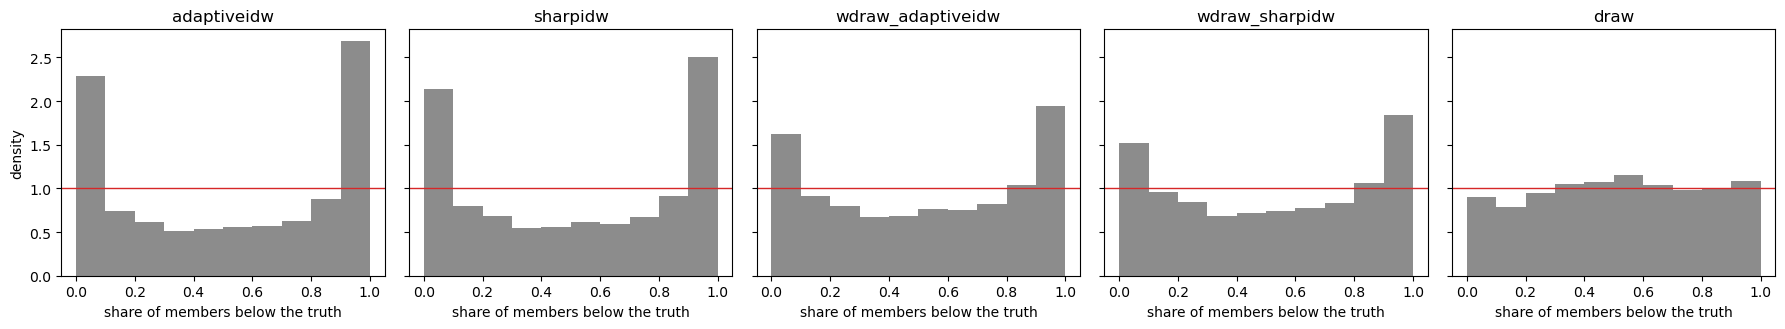

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4), sharey=True)
for ax, name in zip(axes, decoders):
    share_below = np.mean(results[name].esi_samples() <= truth[..., None], axis=-1).ravel()
    ax.hist(share_below, bins=10, range=(0, 1), weights=np.full(share_below.size, 10 / share_below.size),
            color="0.55")
    ax.axhline(1.0, color="C3", lw=1)
    ax.set_title(name)
    ax.set_xlabel("share of members below the truth")
axes[0].set_ylabel("density")
plt.tight_layout()
plt.show()

The averaging decoders pile about a quarter of the grid into each end, so their laws are too narrow,
the truth falling outside the members far too often. The weighted draws flatten the histogram a good
deal, while the uniform draw leaves it almost flat.

### Reading the law

With a calibrated law, the quantiles and the probability of exceedance become the readings to map, in
place of the mean.

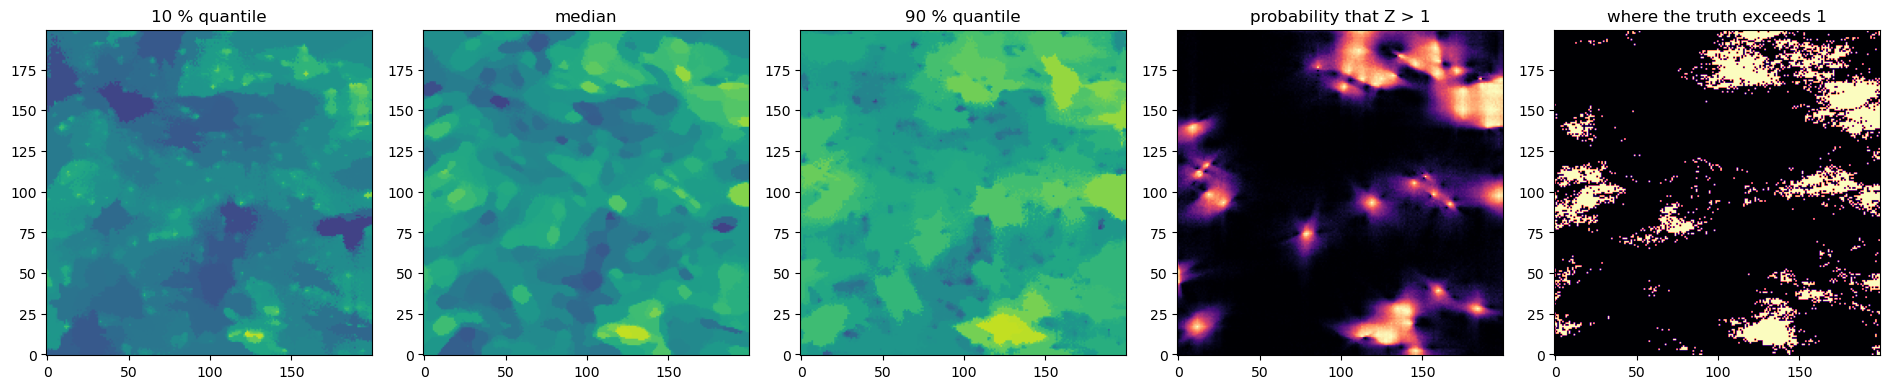

In [6]:
best = results["wdraw_sharpidw"]
members = best.esi_samples()
q10, q50, q90 = (np.nanpercentile(members, q, axis=-1) for q in (10, 50, 90))
p_exceed = np.mean(members > 1.0, axis=-1)
panels = [("10 % quantile", q10, "viridis"), ("median", q50, "viridis"), ("90 % quantile", q90, "viridis"),
          ("probability that Z > 1", p_exceed, "magma"), ("where the truth exceeds 1", (truth > 1).astype(float), "magma")]
fig, axes = plt.subplots(1, 5, figsize=(19, 4))
for ax, (title, f, cmap) in zip(axes, panels):
    bounds = (0, 1) if cmap == "magma" else (truth.min(), truth.max())
    ax.imshow(f.T, origin="lower", cmap=cmap, vmin=bounds[0], vmax=bounds[1])
    ax.set_title(title)
plt.tight_layout()
plt.show()

The band between the 10 % and 90 % quantiles shows where the field could lie. The probability of
exceedance picks out most of the zones where the truth exceeds 1, highest near the data that fall in
them and lower between the data, where 400 of them cannot settle the detail of each zone.

### Far from the data

A draw needs a cell with data to draw from. Where a cell has none, the treatment of empty cells
decides, so the draws pair naturally with `empty_cells="mark"`. With `mark_source="cells"` and
`mark_value="datum"`, an empty cell receives one datum drawn from the cells with data, so the uniform
draw then estimates the theory's block-mark law exactly. To see the difference we keep only the data
in the left half of the field and measure the coverage on the right quarter, far from all of them.

In [7]:
left = points[:, 0] < 100
far = np.zeros((200, 200), bool)
far[130:, :] = True
policies = {"nan": dict(empty_cells="nan"), "coarsen": dict(empty_cells="coarsen"),
            "mark, block-mark": dict(empty_cells="mark", mark_source="cells", mark_value="datum")}
rows = {}
for name, policy in policies.items():
    with spatialize.session.override(**policy):
        r = esi_griddata(points[left], values[left], xi, local_interpolator="draw", n_partitions=200,
                         alpha=alpha, seed=0)
    low, high = np.nanpercentile(r.esi_samples(), [5, 95], axis=-1)
    rows[name] = {"90 % coverage, far from the data": round(np.nanmean(((truth >= low) & (truth <= high))[far]), 2)}
pd.DataFrame(rows).T

,"90 % coverage, far from the data"
nan,0.25
coarsen,0.70
"mark, block-mark",0.77


Under `"nan"` the far zone keeps only the members of the few partitions that reach some datum, so the
band is too narrow and covers the truth a quarter of the time. The marks bring the residual weight of
the law back, raising the coverage to about three quarters, while coarser cells, which continue the
field, reach almost as much. The tutorial *Cells without data* follows
this further.

### Reproducible, location by location

The draws take their random numbers from the seed, the partition and the position of the location in
the list of queries. The same call therefore gives the same members, bit for bit. Another list, or the
same location at another position, gives another realisation of the same law.

In [8]:
kw = dict(local_interpolator="wdraw_adaptiveidw", n_partitions=2000, alpha=alpha, seed=0)
alone = esi_nongriddata(points, values, np.array([[120.0, 80.0]]), **kw).esi_samples()[0]
again = esi_nongriddata(points, values, np.array([[120.0, 80.0]]), **kw).esi_samples()[0]
moved = esi_nongriddata(points, values, np.array([[10.0, 10.0], [190.0, 150.0], [120.0, 80.0]]), **kw).esi_samples()[2]
print(f"same call, identical members {np.array_equal(alone, again)}")
print(f"other position, share of identical members {np.mean(alone == moved):.2f}, "
      f"Kolmogorov–Smirnov p-value {ks_2samp(alone, moved).pvalue:.2f}")
pd.DataFrame({"alone": np.percentile(alone, [10, 50, 90]), "at another position": np.percentile(moved, [10, 50, 90])},
             index=["10 %", "50 %", "90 %"]).round(3)

same call, identical members True
other position, share of identical members 0.39, Kolmogorov–Smirnov p-value 0.99


,alone,at another position
10 %,-1.914,-1.914
50 %,-0.741,-0.741
90 %,1.454,1.454


At another position fewer than half of the members coincide, while their quantiles match, the
Kolmogorov–Smirnov test finding no difference between the two samples. A reading of the law does not
depend on the order of the queries, while a single member does.

### Choosing a drawing decoder

| Purpose | Decoder |
|---|---|
| intervals and probabilities of exceedance on a field with a direction | `wdraw_sharpidw` or `wdraw_adaptiveidw` |
| a calibrated law where the map matters less, or a piecewise-constant field | `draw` |
| a variable with an atom (zeros, detection limits) | `draw` or a weighted draw, read through the median |
| a heavy-tailed variable | a weighted draw, read through the median |
| a known variogram on a smooth field | `wdraw_kriging` |
| a fast baseline on a field without a direction | `wdraw_idw` |

## Pitfalls

- **Reading a draw through its mean map alone.** The mean of the draws is close to the averaging map,
  so the map tells little new. The gain is in the quantiles, the probabilities and the calibration.
- **Comparing members, not laws.** Two runs that list the queries differently give different members
  with the same law. Compare quantiles or probabilities, never single members.
- **Draws far from the data under `"nan"`.** The law there rests on the few partitions that reach some
  datum, so it is too narrow. Pair the draws with `empty_cells="mark"`.
- **Too few partitions.** A law read from the members needs enough of them for its tails. A few hundred
  suit a 90 % interval, more for rarer events.

## Try it yourself

1. Add `"wdraw_kriging"` and `"wdraw_idw"` on the isotropic field of the tutorial on decoders, with the
   variogram given there.
2. Change the threshold of exceedance to 1.5 and compare the Brier scores again.
3. Under `empty_cells="mark"`, compare `mark_value="decoder"` with `"datum"` for the uniform draw.

## Next

- *The decoders*, for the averaging decoders whose weights the draws use.
- *Cells without data*, for the marks in depth.
- *Uncertainty at a location*, to read any ensemble as a law.
- *Rain* and *Heavy tails*, where the draws keep the atom at zero and read the tail through the median.
- The documentation's [Decoders](https://spatialize.readthedocs.io/en/latest/theory/decoders.html) and
  [The block-mark model](https://spatialize.readthedocs.io/en/latest/theory/blockmark.html) (theory).